# EDA: current mock dataset (read from `data/CURRENT.json`)

Read-only EDA. Paths, day count and grid size come from `data/CURRENT.json` and `meta/manifest.json`; nothing is hardcoded. `oracle/` is used only for diagnostic slices.

In [1]:
import json, os
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.dataset as pads, yaml
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / 'data' / 'CURRENT.json').exists():
    ROOT = ROOT.parent
CUR = json.loads((ROOT / 'data/CURRENT.json').read_text())
D = ROOT / CUR['path']
MAN = json.loads((ROOT / CUR['manifest']).read_text())
SCHEMA = yaml.safe_load((ROOT / CUR['schema']).read_text())
N_DAYS, N_HEX = MAN['days'], MAN['hex_count']
STEPS_PER_DAY = 24 * 60 // MAN['snapshot_minutes']
N_TS = N_DAYS * STEPS_PER_DAY

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'figure.figsize': (10, 3.6)})
C = ['#2a6fdb', '#e8743b', '#19a979', '#945ecf', '#ed4a7b', '#13a4b4', '#6c8893']

def read(table, columns=None):
    return pads.dataset(D / table, format='parquet', partitioning='hive').to_table(columns=columns).to_pandas()

print(CUR['dataset_id'], CUR['data_fingerprint'][:12])
print(f"days={N_DAYS} hex={N_HEX} ts={N_TS} case={MAN['case']} {MAN['start_date']} -> {MAN['end_exclusive']}")

hcm_mock_v2_90d_seed42_bounded_tail 027261df6476
days=90 hex=61 ts=25920 case=bounded_tail 2026-01-05 -> 2026-04-05 00:00:00


In [2]:
## 1. Load + integrity
hexes = read('raw/hexes')
snap = read('raw/hex_snapshot')
weather = read('raw/weather')
orders = read('raw/orders')
feat = read('features/hex_features')
for df in (snap, feat, orders, weather):
    df.drop(columns=[c for c in ['date'] if c in df], inplace=True)

counts = {'raw/hexes': len(hexes), 'raw/hex_snapshot': len(snap), 'raw/weather': len(weather),
          'raw/orders': len(orders), 'features/hex_features': len(feat)}
chk = pd.DataFrame({'rows': counts, 'manifest': {k: MAN['row_counts'][k] for k in counts}})
chk['ok'] = chk.rows == chk.manifest
print(chk)
print('grid full:', len(snap) == N_TS * N_HEX, snap.groupby('ts').size().eq(N_HEX).all(),
      snap.ts.nunique() == N_TS, not snap.duplicated(['ts', 'hex_id']).any())
print('snapshot nulls:', snap.isna().sum().sum(), '| feature nulls:', feat.isna().sum().sum(),
      '| non-finite feat:', (~np.isfinite(feat.select_dtypes('number').to_numpy())).sum())
fcols = [c for c in feat.columns if c not in ('ts', 'hex_id')]
print('n features:', len(fcols), '| dtypes:', feat[fcols].dtypes.value_counts().to_dict())
o = orders
print('lifecycle: pickup=>accepted', (o.pickup_ts.isna() | o.accepted_ts.notna()).all(),
      '| dropoff=>pickup', (o.dropoff_ts.isna() | o.pickup_ts.notna()).all(),
      '| not(cancel & pickup)', ~(o.cancel_ts.notna() & o.pickup_ts.notna()).any())
print('surge range:', snap.surge_multiplier.min(), snap.surge_multiplier.max())

                          rows  manifest    ok
raw/hexes                   61        61  True
raw/hex_snapshot       1581120   1581120  True
raw/weather              25920     25920  True
raw/orders             2539401   2539401  True
features/hex_features  1581120   1581120  True


grid full: True True True True


snapshot nulls: 0 | feature nulls: 0 | non-finite feat: 0
n features: 45 | dtypes: {dtype('float32'): 45}
lifecycle: pickup=>accepted True | dropoff=>pickup True | not(cancel & pickup) True
surge range: 1.0 2.7


                        count     mean      std    min     50%     90%  \
demand              1581120.0    1.606    2.025    0.0    1.00    4.00   
supply              1581120.0    2.711    2.422    0.0    2.00    6.00   
effective_supply_t  1581120.0    5.037    3.578    0.0    4.40    9.70   
eta_sec             1581120.0  378.221  182.951  240.0  299.56  637.18   
surge_multiplier    1581120.0    1.125    0.191    1.0    1.00    1.40   

                         99%       max  
demand                 9.000    51.000  
supply                10.000    23.000  
effective_supply_t    16.700    38.100  
eta_sec             1052.304  2750.565  
surge_multiplier       1.800     2.700  
demand>idle 30.42% | demand>S_eff 15.95%
surge>1 48.18% | surge>=2 0.11%


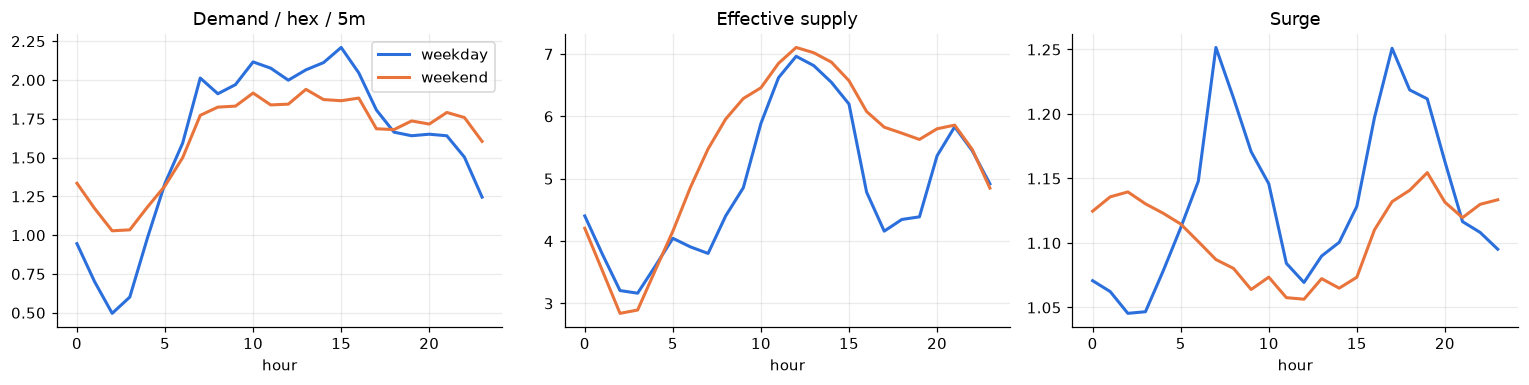

             hexes  demand   idle  s_eff      eta  surge  short
zone                                                           
airport          3   1.061  1.682  3.282  421.705  1.120  0.157
cbd              7   4.069  2.342  7.576  430.302  1.331  0.277
office          11   2.153  2.034  4.699  413.540  1.192  0.275
residential     18   1.797  3.085  5.301  356.070  1.114  0.164
suburb          21   0.348  3.068  4.451  352.944  1.024  0.045
venue            1   2.960  1.601  3.826  424.230  1.283  0.400


In [3]:
## 2. Demand / supply profile
s = snap.merge(hexes[['hex_id', 'zone', 'ring']], on='hex_id')
s = s.merge(feat[['ts', 'hex_id', 'effective_supply_t']], on=['ts', 'hex_id'])
t0 = s.ts - pd.Timedelta(minutes=MAN['snapshot_minutes'])   # window start: day/hour of the window
s['day'] = t0.dt.normalize(); s['hour'] = t0.dt.hour; s['dow'] = t0.dt.dayofweek
s['weekend'] = s.dow >= 5
print(s[['demand', 'supply', 'effective_supply_t', 'eta_sec', 'surge_multiplier']].describe(percentiles=[.5, .9, .99]).round(3).T)
print('demand>idle %.2f%% | demand>S_eff %.2f%%' % (100*(s.demand > s.supply).mean(), 100*(s.demand > s.effective_supply_t).mean()))
print('surge>1 %.2f%% | surge>=2 %.2f%%' % (100*(s.surge_multiplier > 1).mean(), 100*(s.surge_multiplier >= 2).mean()))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for i, (col, title) in enumerate([('demand', 'Demand / hex / 5m'), ('effective_supply_t', 'Effective supply'), ('surge_multiplier', 'Surge')]):
    for j, wk in enumerate([False, True]):
        g = s[s.weekend == wk].groupby('hour')[col].mean()
        ax[i].plot(g.index, g.values, color=C[j], label='weekend' if wk else 'weekday', lw=2)
    ax[i].set_title(title); ax[i].set_xlabel('hour')
ax[0].legend(); plt.tight_layout(); plt.show()

z = s.groupby('zone').agg(hexes=('hex_id', 'nunique'), demand=('demand', 'mean'), idle=('supply', 'mean'),
                          s_eff=('effective_supply_t', 'mean'), eta=('eta_sec', 'mean'), surge=('surge_multiplier', 'mean'),
                          short=('demand', lambda d: (d > s.loc[d.index, 'effective_supply_t']).mean()))
print(z.round(3))

S_eff=0: 2.946% rows | D>0 & S_eff=0: 1.970% rows
D/S_eff quantiles: {0.5: 0.201, 0.9: 1.429, 0.99: 4.286, 0.999: 10.0} | max 12.5
rows >10: 98 (0.0064%) | >15: 0


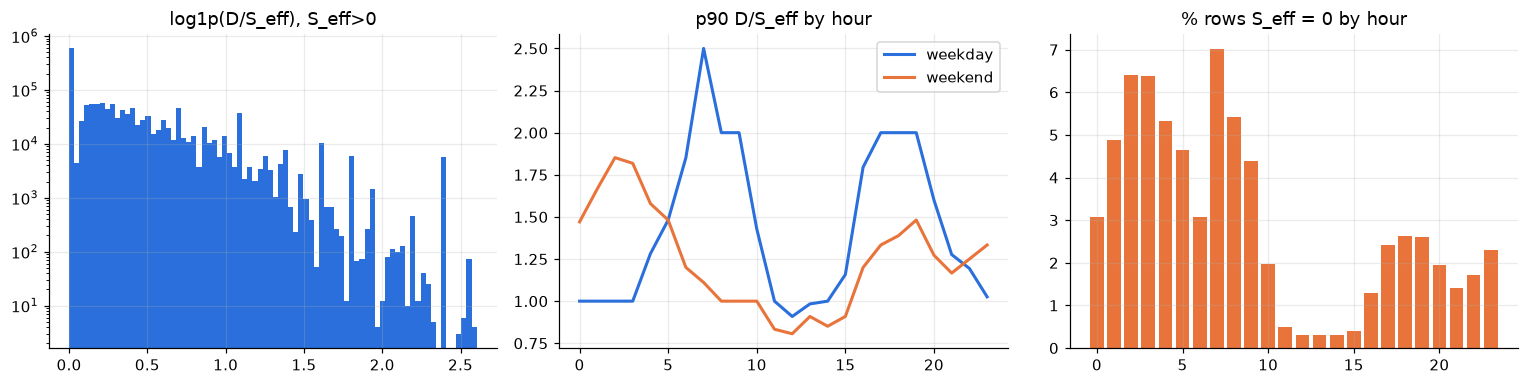

rows D/S_eff > 5 by zone (share of tail):
{'office': 0.356, 'residential': 0.319, 'cbd': 0.118, 'suburb': 0.118, 'airport': 0.048, 'venue': 0.041}
top hours in tail: {7: 968, 8: 681, 17: 626, 18: 610, 19: 548, 9: 523}


In [4]:
## 3. D / S_eff (mask S_eff > 0, no epsilon, no clip)
s_eff = s.effective_supply_t.round(4)
pos = s_eff > 0
ds = s.demand[pos] / s_eff[pos]
print('S_eff=0: %.3f%% rows | D>0 & S_eff=0: %.3f%% rows' % (100*(~pos).mean(), 100*((~pos) & (s.demand > 0)).mean()))
q = ds.quantile([.5, .9, .99, .999]).round(3)
print('D/S_eff quantiles:', q.to_dict(), '| max', round(ds.max(), 3))
print('rows >10: %d (%.4f%%) | >15: %d' % ((ds > 10).sum(), 100*(ds > 10).mean(), (ds > 15).sum()))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(np.log1p(ds), bins=80, color=C[0]); ax[0].set_yscale('log'); ax[0].set_title('log1p(D/S_eff), S_eff>0')
h = s[pos].assign(ds=ds).groupby(['hour', 'weekend']).ds.quantile(.9).unstack()
for j, wk in enumerate([False, True]):
    ax[1].plot(h.index, h[wk], color=C[j], lw=2, label='weekend' if wk else 'weekday')
ax[1].set_title('p90 D/S_eff by hour'); ax[1].legend()
zero = s.assign(z=~pos).groupby('hour').z.mean() * 100
ax[2].bar(zero.index, zero.values, color=C[1]); ax[2].set_title('% rows S_eff = 0 by hour')
plt.tight_layout(); plt.show()

tail = s[pos].assign(ds=ds)[lambda x: x.ds > 5]
print('rows D/S_eff > 5 by zone (share of tail):'); print(tail.zone.value_counts(normalize=True).round(3).to_dict())
print('top hours in tail:', tail.hour.value_counts().head(6).to_dict())

calendar keys: {'profile': 15, 'n_days': 90, 'split': 3, 'rain_days': 15, 'rain_episodes_min': 33, 'venue_events': 11, 'drain_events': 39, 'venue_hex': 15, 'airport_hexes': 3, 'note': 90}


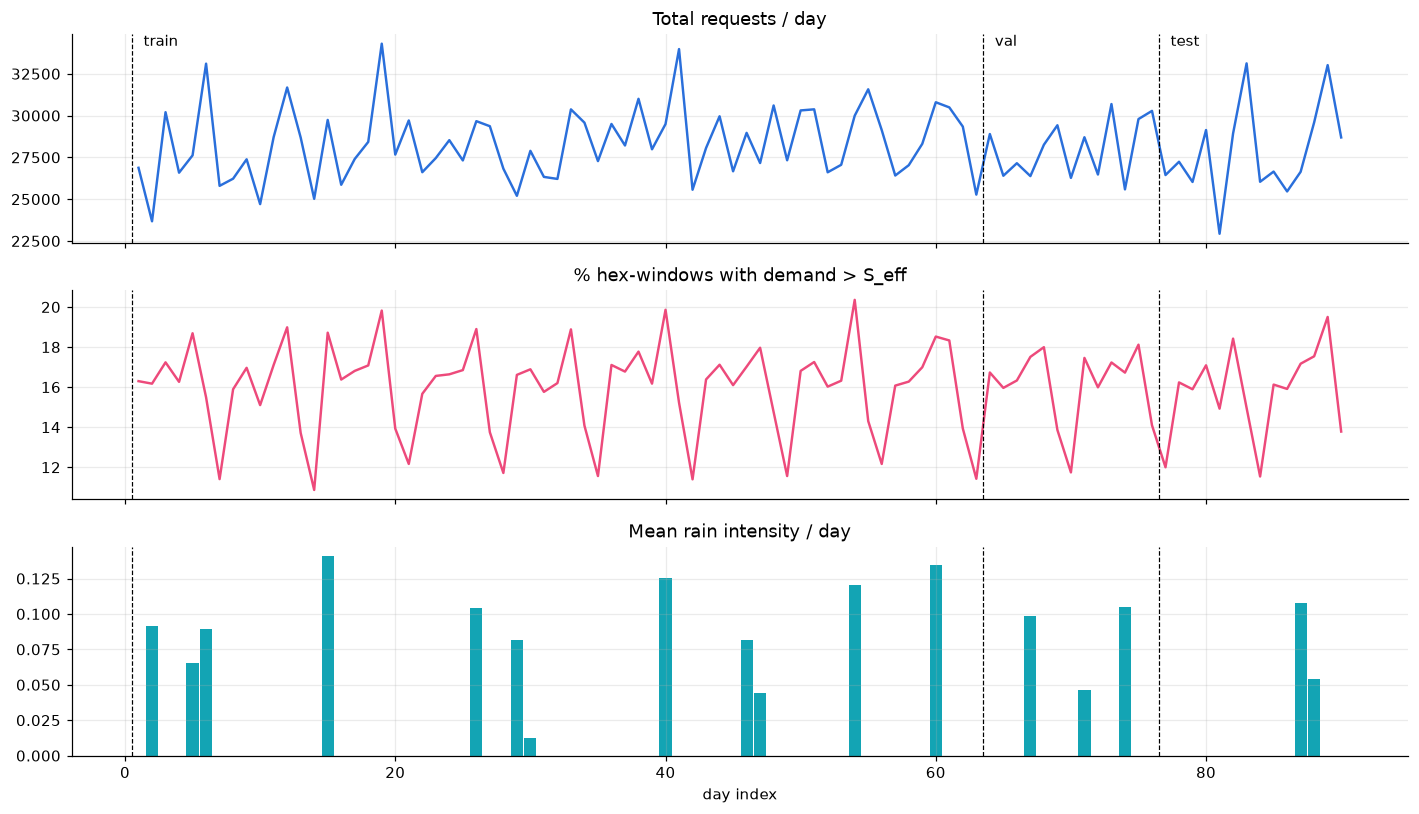

       days  demand   idle  s_eff  surge   rain  short  weekend
part                                                           
train    63   1.613  2.714  5.051  1.126  0.017  0.160    0.286
val      13   1.595  2.680  4.986  1.125  0.019  0.161    0.231
test     14   1.585  2.726  5.025  1.123  0.012  0.158    0.286


          share  demand  s_eff  surge  short
rain_bin                                    
dry       0.974   1.597  5.072  1.122  0.157
mid       0.012   1.857  3.574  1.259  0.273
heavy     0.013   2.017  3.899  1.250  0.245


In [8]:
## 4. Daily trend, rain, calendar, suggested split drift
cal = json.loads((D / 'oracle/calendar.json').read_text())
print('calendar keys:', {k: (len(v) if hasattr(v, '__len__') else v) for k, v in cal.items()})
if 'rain_intensity' not in s:
    s = s.merge(weather[['ts', 'rain_intensity']], on='ts')
s['day_idx'] = (s.day - s.day.min()).dt.days + 1          # 1-based, matches suggested_split_days_inclusive
daily = s.groupby('day_idx').agg(demand=('demand', 'sum'), s_eff=('effective_supply_t', 'mean'),
                                 surge=('surge_multiplier', 'mean'), rain=('rain_intensity', 'mean'))
daily['short'] = s.assign(sh=s.demand > s.effective_supply_t).groupby('day_idx').sh.mean()

split = MAN['suggested_split_days_inclusive']
fig, ax = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True)
ax[0].plot(daily.index, daily.demand, color=C[0], lw=1.6); ax[0].set_title('Total requests / day')
ax[1].plot(daily.index, daily.short * 100, color=C[4], lw=1.6); ax[1].set_title('% hex-windows with demand > S_eff')
ax[2].bar(daily.index, daily.rain, color=C[5], width=.9); ax[2].set_title('Mean rain intensity / day'); ax[2].set_xlabel('day index')
for k, (a0, a1) in split.items():
    for a in ax: a.axvline(a0 - .5, color='k', ls='--', lw=.8)
    ax[0].text(a0, ax[0].get_ylim()[1], f' {k}', va='top')
plt.tight_layout(); plt.show()

s['part'] = pd.cut(s.day_idx, [0] + [v[1] for v in split.values()], labels=list(split))
part = s.groupby('part', observed=True).agg(days=('day_idx', 'nunique'), demand=('demand', 'mean'), idle=('supply', 'mean'),
        s_eff=('effective_supply_t', 'mean'), surge=('surge_multiplier', 'mean'), rain=('rain_intensity', 'mean'),
        short=('demand', lambda d: (d > s.loc[d.index, 'effective_supply_t']).mean()),
        weekend=('weekend', 'mean'))
print(part.round(3))

s['rain_bin'] = pd.cut(s.rain_intensity, [-.01, 0, .3, .6, 1], labels=['dry', 'light', 'mid', 'heavy'])
print(s.groupby('rain_bin', observed=True).agg(share=('demand', 'size'), demand=('demand', 'mean'), s_eff=('effective_supply_t', 'mean'),
      surge=('surge_multiplier', 'mean'), short=('demand', lambda d: (d > s.loc[d.index, 'effective_supply_t']).mean()))
      .assign(share=lambda x: x.share / x.share.sum()).round(3))

mature orders: 2536936
completion 91.98% | cancel before accept 5.51% | cancel after accept 2.51% | open 0.000%


                           count   mean    std   min    50%    90%    99%  \
accept_min             2397147.0   0.23   0.18  0.08   0.21   0.31   1.00   
pickup_min             2333447.0   7.49   3.34  4.08   6.23  12.04  18.57   
trip_min               2333447.0  18.97  12.91  1.58  15.93  36.32  60.89   
est_trip_duration_min  2536936.0  18.81  12.35  3.00  16.45  35.51  58.77   

                          max  
accept_min               8.46  
pickup_min              48.68  
trip_min               153.89  
est_trip_duration_min  109.75  
intra-hex share 0.200


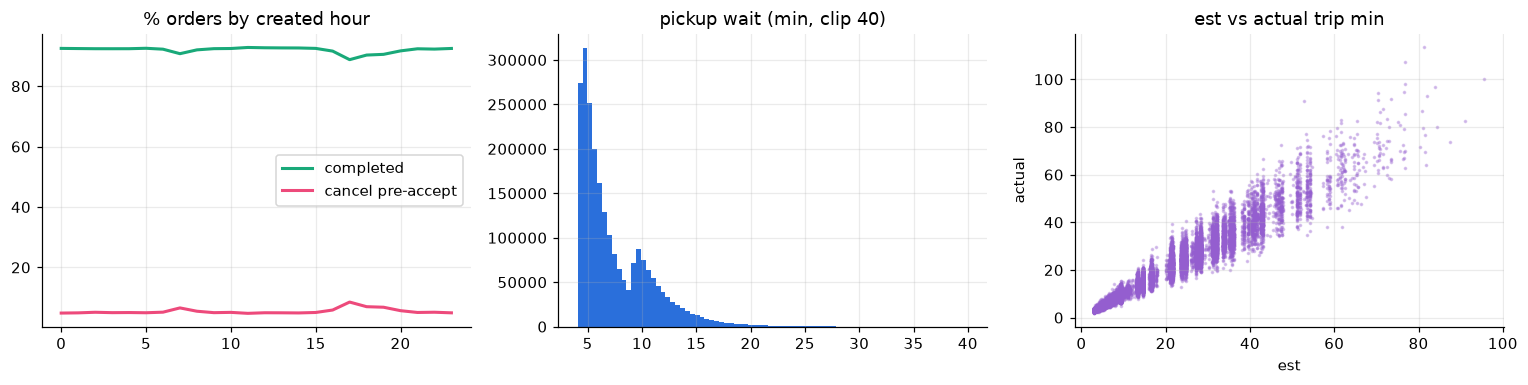

OD pairs used: 3721 of 3721 | top-10 share 0.075


In [9]:
## 5. Orders lifecycle (drop last ~2h of orders: lifecycle censored at end of data)
end = pd.Timestamp(MAN['end_exclusive'])
o = orders[orders.created_ts <= end - pd.Timedelta(hours=2)].copy()
o['hour'] = o.created_ts.dt.hour
o['outcome'] = np.select([o.dropoff_ts.notna(), o.pickup_ts.notna(), o.cancel_ts.notna(), o.accepted_ts.notna()],
                         ['completed', 'in_trip', 'cancelled_after_accept_or_unmatched', 'accepted_open'], 'unmatched_open')
o['cancel_pre_accept'] = o.cancel_ts.notna() & o.accepted_ts.isna()
o['cancel_post_accept'] = o.cancel_ts.notna() & o.accepted_ts.notna()
print('mature orders:', len(o))
print('completion %.2f%% | cancel before accept %.2f%% | cancel after accept %.2f%% | open %.3f%%' % (
    100*o.dropoff_ts.notna().mean(), 100*o.cancel_pre_accept.mean(), 100*o.cancel_post_accept.mean(),
    100*(o.dropoff_ts.isna() & o.cancel_ts.isna()).mean()))
mins = lambda a, b: (o[b] - o[a]).dt.total_seconds() / 60
o['accept_min'] = mins('created_ts', 'accepted_ts'); o['pickup_min'] = mins('created_ts', 'pickup_ts'); o['trip_min'] = mins('pickup_ts', 'dropoff_ts')
print(o[['accept_min', 'pickup_min', 'trip_min', 'est_trip_duration_min']].describe(percentiles=[.5, .9, .99]).round(2).T)
print('intra-hex share %.3f' % (o.origin_hex == o.dest_hex).mean())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
hc = o.groupby('hour').agg(comp=('dropoff_ts', lambda x: x.notna().mean()), canc=('cancel_pre_accept', 'mean'))
ax[0].plot(hc.index, hc.comp * 100, color=C[2], lw=2, label='completed'); ax[0].plot(hc.index, hc.canc * 100, color=C[4], lw=2, label='cancel pre-accept')
ax[0].set_title('% orders by created hour'); ax[0].legend()
ax[1].hist(o.pickup_min.dropna().clip(upper=40), bins=80, color=C[0]); ax[1].set_title('pickup wait (min, clip 40)')
done = o.dropna(subset=['trip_min'])
ax[2].scatter(done.est_trip_duration_min.sample(20000, random_state=0), done.trip_min.sample(20000, random_state=0), s=2, alpha=.3, color=C[3])
ax[2].set_title('est vs actual trip min'); ax[2].set_xlabel('est'); ax[2].set_ylabel('actual')
plt.tight_layout(); plt.show()
od = o.groupby(['origin_hex', 'dest_hex']).size().sort_values(ascending=False)
print('OD pairs used:', len(od), 'of', N_HEX**2, '| top-10 share %.3f' % (od.head(10).sum() / od.sum()))

In [10]:
## 6. Features: contract, formula checks, zero share, correlation
contract = json.loads((D / 'meta/feature_contract.json').read_text())
node_cols = contract['node_features']
print('contract keys:', list(contract)[:12])
print('node feature list len:', None if node_cols is None else len(node_cols), '| extra columns in table:',
      [c for c in fcols if node_cols and c not in node_cols])

f = feat.merge(snap[['ts', 'hex_id', 'demand', 'supply', 'eta_sec', 'surge_multiplier']], on=['ts', 'hex_id'])
chk = {
    'demand_5m == raw demand': np.allclose(f.demand_5m, f.demand),
    'idle_supply_t == raw supply': np.allclose(f.idle_supply_t, f.supply),
    'eta_sec_t == raw eta': np.allclose(f.eta_sec_t, f.eta_sec, atol=1e-2),
    'current_surge_t == raw surge': np.allclose(f.current_surge_t, f.surge_multiplier, atol=1e-5),
    'local_pressure_log formula': np.allclose(f.local_pressure_log_t, np.log1p(f.demand_5m) - np.log1p(f.idle_supply_t), atol=1e-4),
    'S_eff formula': np.allclose(f.effective_supply_t, f.idle_supply_t + f.arriving_trip_count_eta_0_5_t
                                 + .5 * f.arriving_trip_count_eta_5_10_t + .2 * f.arriving_trip_count_eta_10_15_t, atol=1e-3),
    'history_steps min': float(f.history_steps_available.min()),
}
for k, v in chk.items(): print(f'{k:32s} {v}')

desc = feat[fcols].describe().T[['mean', 'std', 'min', 'max']]
desc['zero_share'] = (feat[fcols] == 0).mean()
desc['n_unique'] = feat[fcols].nunique()
print(desc.round(3).to_string())

contract keys: ['version', 'node_features', 'edge_features', 'support_columns', 'node_dim', 'edge_dim', 'rates', 'pickup_wait_p90_30m', 'supply_buckets', 'edges', 'travel_prior', 'support_usage']
node feature list len: 40 | extra columns in table: ['mature_request_count_15m', 'matched_within_5m_count', 'cancelled_within_5m_count', 'pickup_wait_support_30m', 'history_steps_available']


demand_5m == raw demand          True
idle_supply_t == raw supply      True
eta_sec_t == raw eta             True
current_surge_t == raw surge     True
local_pressure_log formula       True
S_eff formula                    True
history_steps min                12.0


                                    mean      std      min       max  zero_share  n_unique
demand_5m                          1.606    2.025    0.000    51.000       0.382        36
idle_supply_t                      2.711    2.422    0.000    23.000       0.196        24
backlog_t                          0.070    0.278    0.000     8.000       0.935         8
eta_sec_t                        378.221  182.951  240.000  2750.565       0.000   1423648
local_pressure_log_t              -0.369    1.071   -3.178     3.951       0.119       231
demand_sum_15m                     4.818    4.927    0.000    96.000       0.160        78
demand_mean_60m                    1.606    1.486    0.000    20.917       0.020       195
demand_std_60m                     1.148    0.760    0.000    14.463       0.021      1386
demand_momentum_15m                0.000    3.377  -50.000    81.000       0.201        89
idle_supply_mean_15m               2.711    2.122    0.000    19.000       0.058        58

                   level_0                    level_1     rho
od_destination_entropy_30m             od_support_30m  0.9656
    match_rate_matured_15m    cancel_rate_matured_15m -0.9637
           demand_mean_60m             od_support_30m  0.9612
            demand_sum_15m             od_support_30m  0.9387
        pickup_outflow_15m             od_support_30m  0.9324
           demand_mean_60m             demand_std_60m  0.9315
           demand_mean_60m od_destination_entropy_30m  0.9301
            demand_sum_15m od_destination_entropy_30m  0.9049
            demand_sum_15m            demand_mean_60m  0.9009
match+cancel rate == 1 + 1/(n+2)? False


mature_request_count_15m == demand_sum_15m lagged 5m? 1.0 | same ts: 0.3571


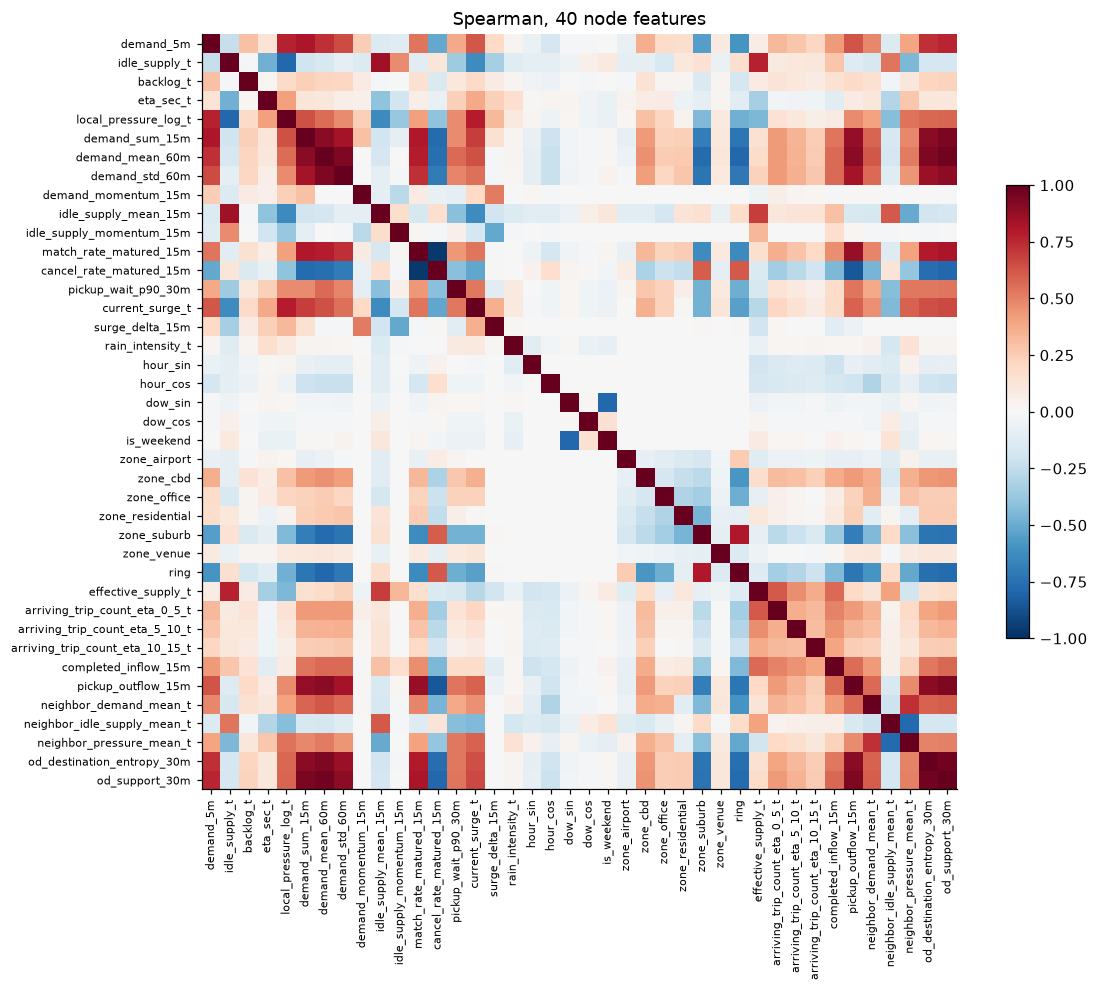

In [11]:
## 6b. Redundancy among node features (Spearman on a 200k-row sample)
smp = feat[node_cols].sample(200_000, random_state=0)
rho = smp.rank().corr()
pairs = rho.where(np.triu(np.ones(rho.shape, bool), 1)).stack().rename('rho').reset_index()
print(pairs.loc[pairs.rho.abs() > .9].sort_values('rho', key=abs, ascending=False).round(4).to_string(index=False))
print('match+cancel rate == 1 + 1/(n+2)?', np.allclose(feat.match_rate_matured_15m + feat.cancel_rate_matured_15m,
      1 + 1 / (feat.mature_request_count_15m + 2), atol=1e-4))
print('mature_request_count_15m == demand_sum_15m lagged 5m?',
      (feat.sort_values(['hex_id', 'ts']).groupby('hex_id').demand_sum_15m.shift(1)
       .eq(feat.sort_values(['hex_id', 'ts']).mature_request_count_15m)).mean().round(4),
      '| same ts:', (feat.mature_request_count_15m == feat.demand_sum_15m).mean().round(4))

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(rho, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(node_cols)), node_cols, rotation=90, fontsize=7); ax.set_yticks(range(len(node_cols)), node_cols, fontsize=7)
ax.grid(False); fig.colorbar(im, shrink=.6); ax.set_title('Spearman, 40 node features'); plt.tight_layout(); plt.show()

partitions: 90 | sampled ['2026-01-07', '2026-01-11'] | rows 506501 | manifest total 23149322
      mean    min    50%     max
n    879.3  524.0  872.0  1132.0
adj  312.0  312.0  312.0   312.0
od   567.3  212.0  560.0   820.0
adjacent & od both 1: 0 | self loops (OD): 23682


                           count    mean     std    min     50%     90%  \
distance_km             326789.0   6.698   3.886  0.000   6.888  11.968   
travel_time_est_min     326789.0  21.852  11.365  2.053  21.192  37.083   
od_requests_5m          326789.0   0.171   0.420  0.000   0.000   1.000   
od_requests_30m         326789.0   1.028   1.045  0.000   1.000   2.000   
od_in_trip_count_t      326789.0   0.576   0.624  0.000   1.000   1.000   
od_transition_prob_30m  326789.0   0.058   0.049  0.002   0.050   0.121   

                           99%      max  
distance_km             16.372   21.054  
travel_time_est_min     52.884  108.244  
od_requests_5m           2.000    7.000  
od_requests_30m          5.000   17.000  
od_in_trip_count_t       2.000    6.000  
od_transition_prob_30m   0.231    0.504  


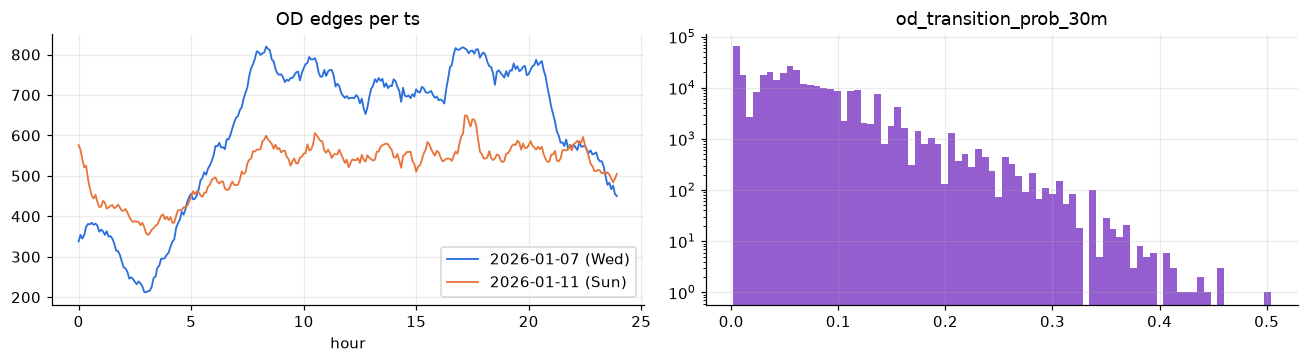

In [14]:
## 7. Graph edges (one weekday + one weekend partition, to keep RAM small)
edge_ds = pads.dataset(D / 'features/graph_edges', format='parquet', partitioning='hive')
dates = sorted({p.split('date=')[1].split('/')[0].split('\\')[0] for p in edge_ds.files})
pick = [d for d in dates if pd.Timestamp(d).dayofweek == 2][:1] + [d for d in dates if pd.Timestamp(d).dayofweek == 6][:1]
e = edge_ds.to_table(filter=pads.field('date').isin(pick)).to_pandas()
print('partitions:', len(dates), '| sampled', pick, '| rows', len(e), '| manifest total', MAN['row_counts']['features/graph_edges'])
per_ts = e.groupby('ts').agg(n=('src_hex', 'size'), adj=('edge_is_adjacent', 'sum'), od=('edge_is_od', 'sum'))
print(per_ts.describe().round(1).T[['mean', 'min', '50%', 'max']])
print('adjacent & od both 1:', int(((e.edge_is_adjacent == 1) & (e.edge_is_od == 1)).sum()),
      '| self loops (OD):', int((e.src_hex == e.dst_hex).sum()))
od_e = e[e.edge_is_od == 1]
print(od_e[['distance_km', 'travel_time_est_min', 'od_requests_5m', 'od_requests_30m', 'od_in_trip_count_t', 'od_transition_prob_30m']]
      .describe(percentiles=[.5, .9, .99]).round(3).T)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for j, d in enumerate(pick):
    g = per_ts[(per_ts.index - pd.Timedelta(minutes=5)).normalize() == pd.Timestamp(d)]
    w0 = g.index - pd.Timedelta(minutes=5)   # window start keeps the 00:00 snapshot at the end of its day
    ax[0].plot((w0 - w0.normalize()).total_seconds() / 3600, g.od, color=C[j], lw=1.2, label=f'{d} ({pd.Timestamp(d).day_name()[:3]})')
ax[0].set_title('OD edges per ts'); ax[0].set_xlabel('hour'); ax[0].legend()
ax[1].hist(od_e.od_transition_prob_30m, bins=80, color=C[3]); ax[1].set_yscale('log'); ax[1].set_title('od_transition_prob_30m')
plt.tight_layout(); plt.show()
del e, od_e

     signal  active_%  short_on_%  short_off_%  surge_on  surge_off top_zone
    s1_ramp   100.000      15.955          NaN     1.125        NaN   suburb
   s2_drain     2.150      76.647       14.621     1.460      1.118   office
 s3_airport     1.434      31.257       15.732     1.271      1.123  airport
   s4_venue     0.019      37.294       15.950     1.571      1.125    venue
    s5_rain     2.577      25.839       15.693     1.254      1.122   suburb
  s6_sparse    34.426       4.454       21.992     1.024      1.178   suburb
s7_boundary     8.197      11.844       16.322     1.085      1.129  airport
rows with no signal active: 0.00%


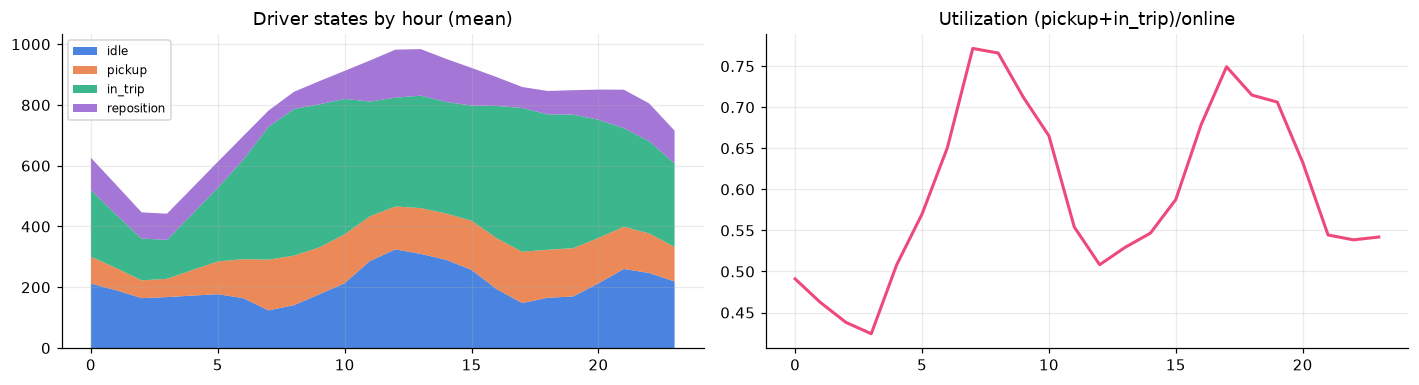

online drivers: mean 782, min 353, max 1103


In [15]:
## 8. Oracle diagnostics (never model input): installed signals S1-S7 and driver states
sig = read('oracle/signal_truth').drop(columns=['date'], errors='ignore')
scols = [c for c in sig.columns if c.startswith('s') and c[1].isdigit()]
m = sig.merge(s[['ts', 'hex_id', 'demand', 'effective_supply_t', 'surge_multiplier', 'zone']], on=['ts', 'hex_id'])
m['short'] = m.demand > m.effective_supply_t
rows = []
for c in scols:
    on = m[c] > 0
    rows.append({'signal': c, 'active_%': 100 * on.mean(), 'short_on_%': 100 * m.short[on].mean(), 'short_off_%': 100 * m.short[~on].mean(),
                 'surge_on': m.surge_multiplier[on].mean(), 'surge_off': m.surge_multiplier[~on].mean(),
                 'top_zone': m.zone[on].mode().iat[0] if on.any() else None})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print('rows with no signal active: %.2f%%' % (100 * (m[scols] <= 0).all(axis=1).mean()))

drv = read('oracle/driver_stats').drop(columns=['date'], errors='ignore')
drv['hour'] = (drv.ts - pd.Timedelta(minutes=5)).dt.hour
busy = (drv.pickup + drv.in_trip) / drv.online
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
hs = drv.groupby('hour')[['idle', 'pickup', 'in_trip', 'reposition']].mean()
ax[0].stackplot(hs.index, hs.T.values, labels=hs.columns, colors=C[:4], alpha=.85); ax[0].legend(loc='upper left', fontsize=8); ax[0].set_title('Driver states by hour (mean)')
ax[1].plot(drv.groupby('hour').apply(lambda g: ((g.pickup + g.in_trip) / g.online).mean()), color=C[4], lw=2); ax[1].set_title('Utilization (pickup+in_trip)/online')
plt.tight_layout(); plt.show()
print('online drivers: mean %.0f, min %.0f, max %.0f' % (drv.online.mean(), drv.online.min(), drv.online.max()))

## 9. Summary (dataset `hcm_mock_v2_90d_seed42_bounded_tail`, fingerprint `027261df…`)

**Integrity**: all row counts match the manifest; complete `(ts, hex)` grid (25,920 × 61); no nulls or non-finite values; all 45 feature columns float32 (40 node features + 5 support counts); lifecycle constraints hold; raw ↔ feature identities (`demand_5m`, `idle_supply_t`, `eta_sec_t`, `current_surge_t`, `local_pressure_log_t`, `effective_supply_t`) match exactly.

**D/S_eff** (S_eff > 0 only): p50 0.201, p90 1.429, p99 4.286, p99.9 10.0, max 12.5; 98 rows > 10, 0 rows > 15. S_eff = 0 on 2.95% of rows (1.97% with D > 0). Matches `docs/data/metadata.md` §7 exactly. The tail sits in office/residential at 07–09h and 17–19h.

**Patterns**
- Weekday: two clear peaks in surge, utilization and D/S (07–08h, 17–19h). Weekend is flatter, with a night peak (00–03h).
- Zones: CBD has the highest demand (4.07/hex/5m) and surge (1.33). Venue (1 hex) has the highest shortage share (40%). Suburb is near-idle (4.5% short; `s6_sparse` covers 34% of rows).
- Rain is rare (2.6% of windows, 15 days). When raining, S_eff drops about 25–30% and shortage rises from 15.7% to 24–27%. No "light" rain (0–0.3) bin appears.
- Surge is in [1, 2.7]; surge > 1 on 48% of rows, ≥ 2 on only 0.11%.
- Orders: 91.98% completion, 5.5% cancel before accept, 2.5% after. Pickup wait is bimodal (~5 and ~10 min). Actual trip time tracks the estimate closely. 20% of trips are intra-hex; all 3,721 OD pairs appear.
- Suggested split 63/13/14 days: means are stable across train/val/test (demand 1.61/1.60/1.59, shortage 16.0/16.1/15.8%). Val has fewer weekend days (23% vs 29%). The test set has only 2 rain days.

**Things to watch in modelling**
- `history_steps_available` is constant (12). It carries no information.
- `mature_request_count_15m` = `demand_sum_15m` lagged by one step. `match_rate` and `cancel_rate` are ρ ≈ −0.96. The `od_support_30m` / `od_destination_entropy_30m` / `demand_mean_60m` group has |ρ| > 0.93 with each other.
- `s1_ramp` is non-zero on every row, so a binary on/off slice is meaningless for it; use its magnitude.
- `s2_drain` is the strongest shortage signal (76.6% short when on vs 14.6% off). This is the signal a graph model needs to capture.